In [ ]:
# Initialisation

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import umap

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

SEED = 0
SAMPLES_PER_CLASS = 500
CLASS_IDS = list(range(10))

np.random.seed(SEED)
torch.manual_seed(SEED)

/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


100%|███████████████████████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:02<00:00, 4.25MB/s]
100%|████████████████████████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 285kB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 2.31MB/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 4.18MB/s]


MNIST: (5000, 784)


/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/kleinq/Documents/M1/DLCV/.venv/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


MNIST embedding: (5000, 2)


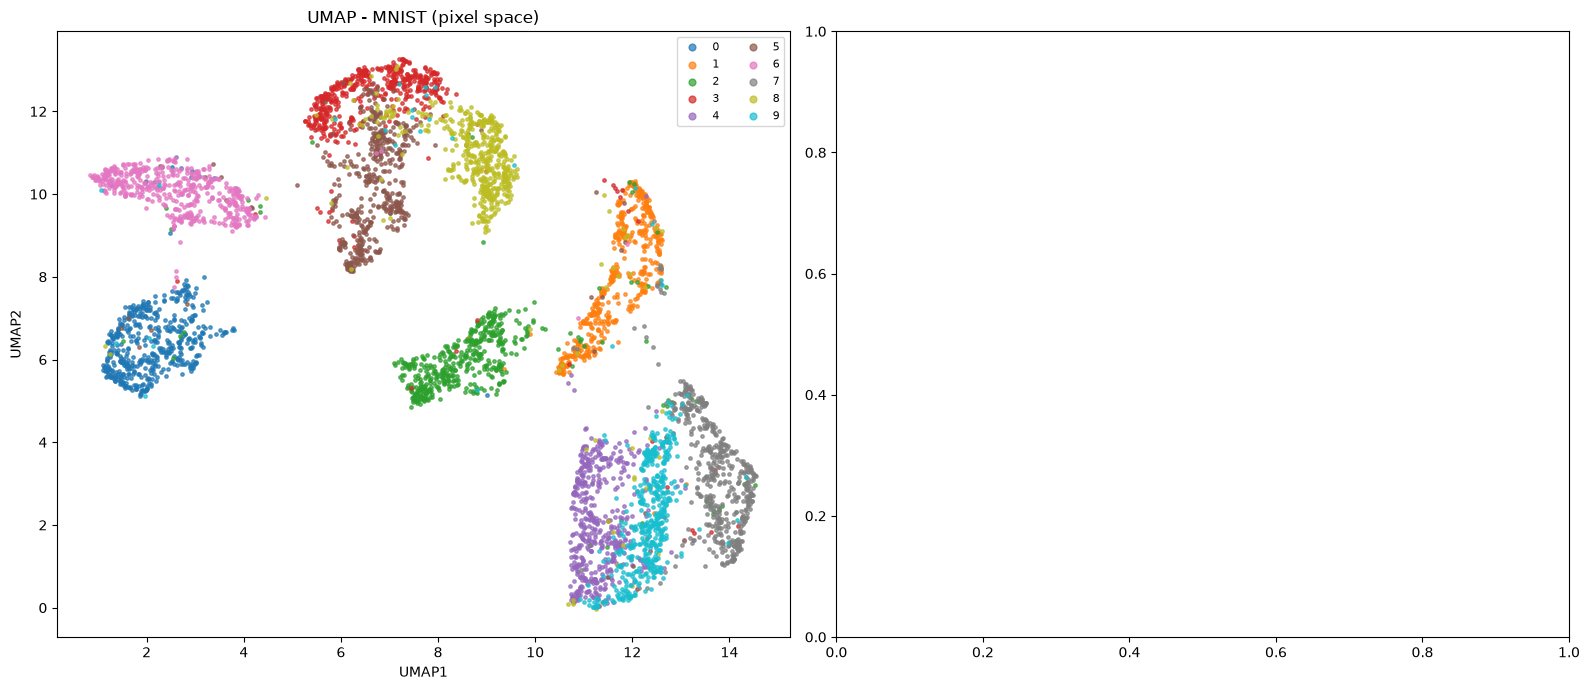

In [ ]:
# Experiment 0

mnist = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
"""
imagenet_transform = transforms.Compose([
  transforms.Resize((64,64)),
  transforms.ToTensor()
])
imagenet = datasets.ImageNet(root="/path/to/imagenet", split="train", transform=imagenet_transform)
"""

def balanced_subset(dataset, class_ids, n_per_class=500, seed=0):
  rng = np.random.default_rng(seed)
  targets = np.asarray(dataset.targets)
  selected_indices = []
  for class_id in class_ids:
    candidates = np.flatnonzero(targets == class_id)
    if len(candidates) < n_per_class:
      raise ValueError(f"Class {class_id} has only {len(candidates)} images.")
    indices = rng.choice(candidates, size=n_per_class, replace=False)
    selected_indices.extend(indices.tolist())
  rng.shuffle(selected_indices)
  return Subset(dataset, selected_indices)

mnist_subset = balanced_subset(mnist, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

# imagenet_subset = balanced_subset(imagenet, CLASS_IDS, SAMPLES_PER_CLASS, SEED)

def extract_pixels(dataset, batch_size=128):
  loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
  features=[]
  labels=[]
  for images, targets in loader:
    flattened = images.flatten(start_dim=1)
    features.append(flattened.numpy())
    labels.append(targets.numpy())
  X = np.concatenate(features, axis=0).astype(np.float32)
  y = np.concatenate(labels, axis=0)
  return X, y

X_mnist, y_mnist = extract_pixels(mnist_subset)
# X_imagenet, y_imagenet = extract_pixels(imagenet_subset)

print("MNIST:", X_mnist.shape)
# print("ImageNet:", X_imagenet.shape)

def run_umap(X, n_neighbors=15, min_dist=0.1, seed=0):
  reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, metric="euclidean", random_state=seed, low_memory=True)
  embedding = reducer.fit_transform(X)
  return embedding

embedding_mnist = run_umap(X_mnist)
# embedding_imagenet = run_umap(X_imagenet)
print("MNIST embedding:", embedding_mnist.shape)
# print("ImageNet embedding:", embedding_imagenet.shape)

def plot_umap(embedding, labels, class_names, title, ax):
  colors = plt.get_cmap("tab10")
  for class_id in np.unique(labels):
    mask = labels == class_id
    ax.scatter(embedding[mask, 0], embedding[mask, 1], color=colors(int(class_id)), label=class_names[int(class_id)], s=6, alpha=0.7, rasterized=True)
  ax.set_title(title)
  ax.set_xlabel("UMAP1")
  ax.set_ylabel("UMAP2")
  ax.legend(markerscale=2, fontsize=8, ncol=2)

mnist_names = [str(i) for i in range(10)]
# imagenet_names = [name[0] is isinstance(name, (tuple, list)) else name for name in imagenet.classes[:10]]
fig, axes = plt.subplots(1, 2, figsize=(16,7))
plot_umap(embedding_mnist, y_mnist, mnist_names, "UMAP - MNIST (pixel space)", axes[0])
# plot_umap(embedding_imagenet, y_imagenet, imagenet_names, "UMAP - ImageNet (pixel space)", axes[1])
plt.tight_layout()
plt.savefig("umap_pixel_space.png", dpi=200, bbox_inches="tight")
plt.show()

# Expérience 0

En projetant les données MNIST d'entraînement avec UMAP, on peut observer que la plupart des classes sont déjà bien séparées: on peut supposer que le jeu de données possède une certaine structure dans le domaine des pixels. Cependant, certaines classes sont tout de même très proches (3, 5 et 8, et 4, 9 et 7): la projection UMAP ne classifiant pas, elle préserve simplement les relations de voisinage dans les données. C'est particulièrement visible pour 3, 5, et 8 qui, manuscrits, peuvent être assez similaires visuellement. On ne peut donc pas tirer une conclusion véritablement sémantique de UMAP.

(TODO: ImageNet)